In [ ]:
'''
Latar Belakang Masalah

Manajemen TechStore ingin memahami pola penjualan produk mereka. Mereka ingin mengetahui:

    Data Numerik: Bagaimana distribusi total pendapatan (Total_Pendapatan), pendapatan rata-rata, dan apakah ada transaksi ekstrem (outlier)?

    Data Kategorikal: Kategori produk mana (Kategori) yang menyumbang transaksi terbanyak?

    Gabungan (Numerik vs Kategorikal): Bagaimana persebaran dan total pendapatan berdasarkan kategori produk?
'''

In [3]:
import matplotlib.pyplot as plt 
import seaborn as sns
import pandas as pd
import numpy as np 

In [4]:
# Set seed agar hasil data acak selalu sama saat dijalankan ulang
np.random.seed(42)

# 1. Menyiapkan Data Dummy
n_data = 100
kategori_list = ["Laptop", "Smartphone", "Aksesori", "Tablet"]
pembayaran_list = ["Transfer", "Kartu Kredit", "E-Wallet"]

data = {
    "ID_Transaksi": range(1, n_data + 1),
    "Kategori": np.random.choice(
        kategori_list, size=n_data, p=[0.2, 0.4, 0.3, 0.1]
    ),
    "Metode_Pembayaran": np.random.choice(pembayaran_list, size=n_data),
    "Jumlah_Terjual": np.random.randint(1, 6, size=n_data),
    "Harga_Satuan": np.random.choice(
        [150000, 500000, 3000000, 8000000, 12000000], size=n_data
    ),
}

df = pd.DataFrame(data)

# Hitung Total Pendapatan (Fitur Numerik Utama)
df["Total_Pendapatan"] = df["Jumlah_Terjual"] * df["Harga_Satuan"]

# Sengaja menambahkan 2 transaksi anomali/outlier (Penjualan Borongan Besar)
df.loc[15, "Total_Pendapatan"] = 65000000
df.loc[42, "Total_Pendapatan"] = 72000000

print("--- 5 Data Teratas ---")
print(df.head())

--- 5 Data Teratas ---
   ID_Transaksi    Kategori Metode_Pembayaran  Jumlah_Terjual  Harga_Satuan  \
0             1  Smartphone          E-Wallet               4      12000000   
1             2      Tablet          E-Wallet               4      12000000   
2             3    Aksesori          Transfer               3        150000   
3             4  Smartphone          Transfer               4       3000000   
4             5      Laptop      Kartu Kredit               3        500000   

   Total_Pendapatan  
0          48000000  
1          48000000  
2            450000  
3          12000000  
4           1500000  


In [8]:
# rangkuman statistika deskriptif

print(df[["Jumlah_Terjual","Harga_Satuan", "Total_Pendapatan"]].describe())
print(df['Kategori'].value_counts())

       Jumlah_Terjual  Harga_Satuan  Total_Pendapatan
count      100.000000  1.000000e+02      1.000000e+02
mean         2.920000  4.713500e+06      1.673950e+07
std          1.404754  4.805793e+06      2.045916e+07
min          1.000000  1.500000e+05      1.500000e+05
25%          1.000000  5.000000e+05      1.000000e+06
50%          3.000000  3.000000e+06      8.000000e+06
75%          4.000000  8.000000e+06      3.200000e+07
max          5.000000  1.200000e+07      7.200000e+07
Kategori
Smartphone    35
Aksesori      28
Laptop        28
Tablet         9
Name: count, dtype: int64


In [17]:
# set tampilan seaborn

sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))


<Figure size 1600x1200 with 0 Axes>

<Figure size 1600x1200 with 0 Axes>

/tmp/ipykernel_62278/2347129649.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_62278/2347129649.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


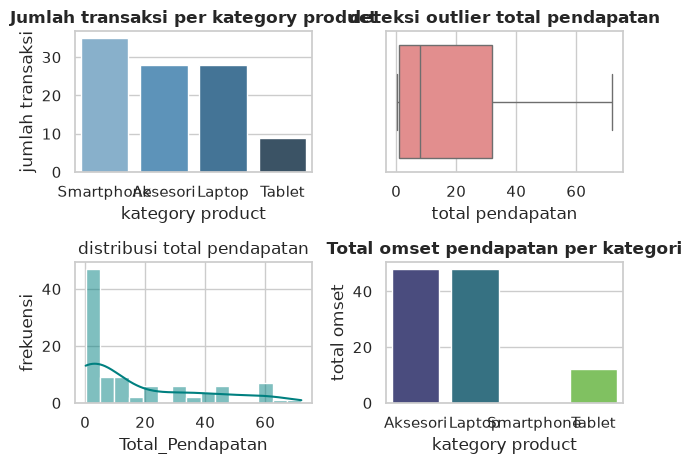

In [22]:
# chart 1: visualisasi data categorical (count plot)
plt.subplot(2, 2, 1)
sns.countplot(
    data=df,
    x="Kategori",
    order=df["Kategori"].value_counts().index,
    palette="Blues_d",
)
plt.title(
    "Jumlah transaksi per kategory product",
    fontsize = 12,
    fontweight="bold",

)

plt.xlabel("kategory product")
plt.ylabel("jumlah transaksi")

# Chart 2: Visualisasi Data Numerik & Outlier (Box Plot)
plt.subplot(2,2,2)
sns.boxplot(x=df["Total_Pendapatan"] / 1e6 , color='lightcoral')
plt.title("deteksi outlier total pendapatan", fontsize=12, fontweight='bold')
plt.xlabel("total pendapatan")

# Chart 3: Distribusi Data Numerik (Histplot + KDE)

plt.subplot(2,2,3)
sns.histplot(df["Total_Pendapatan"] / 1e6, kde=True, color='teal', bins=15)
plt.title("distribusi total pendapatan" )
plt.ylabel("frekuensi")

# Chart 4: Gabungan Numerik vs Kategorikal (Bar Plot - Total Revenue)

plt.subplot(2,2,4)
total_rev_per_cat = (df.groupby("Kategori")["Total_Pendapatan"].sum().reset_index())
sns.barplot(
    data=total_rev_per_cat,
    x="Kategori",
    y=df["Total_Pendapatan"]/1e6,
    palette='viridis',
)

plt.title("Total omset pendapatan per kategori",fontsize=12,fontweight="bold",)
plt.xlabel("kategory product")
plt.ylabel("total omset")

plt.tight_layout()
plt.show()